In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

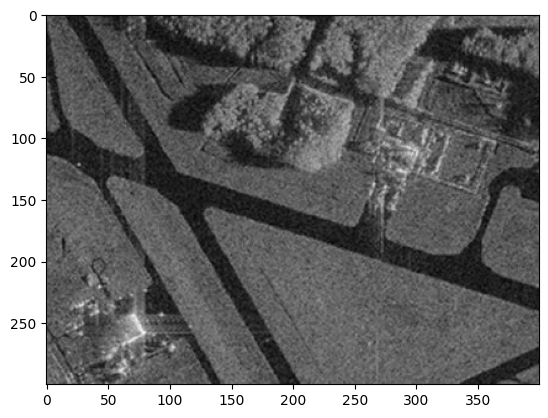

In [3]:
plt.imshow(image_gray, cmap="gray")

# 1. Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [4]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [5]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1

    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)

        mask += local_mask

    return mask*255

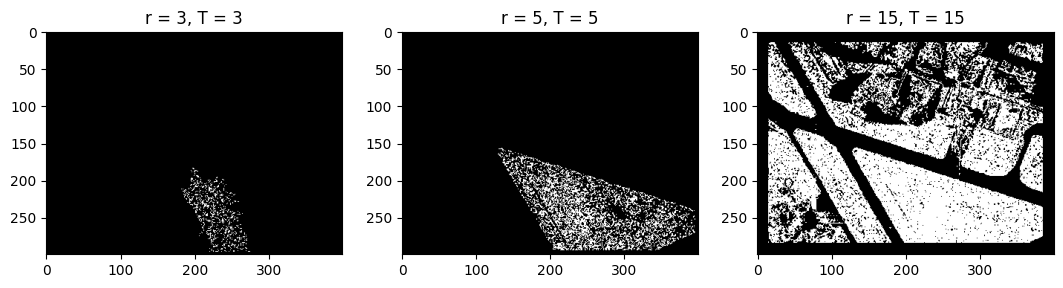

In [6]:
seed_point = (250,250)
_, plots = plt.subplots(1, 3, figsize=(13, 7))

param = [3, 5, 15]

for i in range(0, 3):
    plots[i].set_title('r = {}, T = {}'.format(param[i], param[i]))
    mask = region_growing(image_gray, seed_point, homo_average, param[i], param[i])
    plots[i].imshow(mask, cmap = 'gray') 

plt.show()

# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [7]:
def homo_median(img, mask, point, T):
    med = np.median(img[mask > 0])
    
    if abs(med - img[point]) <= T:
        return True

    return False

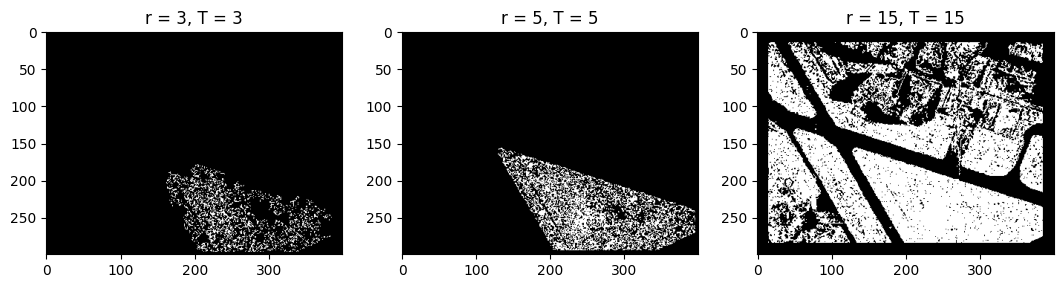

In [8]:
seed_point = (250,250)
_, plots = plt.subplots(1, 3, figsize=(13, 7))

param = [3, 5, 15]

for i in range(0, 3):
    plots[i].set_title('r = {}, T = {}'.format(param[i], param[i]))
    mask = region_growing(image_gray, seed_point, homo_median, param[i], param[i])
    plots[i].imshow(mask, cmap = 'gray') 

plt.show()

Вывод: Алгоритм разрастания регионов с критериями отбора на основе среднего значения и медины не дает существенных отличий

# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

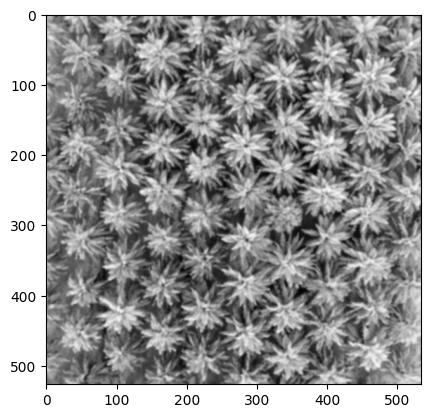

In [9]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_blur = cv2.GaussianBlur(image_gray, (5, 5), 0)
plt.imshow(image_blur, cmap="gray")

In [19]:
ret, thresh = cv2.threshold(image_blur, 0,255, cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist, 0.55 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)
markers = cv2.watershed(image, markers)
print("Деревьев: ", markers.max()+1)

Деревьев:  81
